# Stage 5: End-to-End Pipeline and Final Evaluation

This notebook ties Stages 2–4 together and produces the two prediction files needed for evaluation:

- `dev-claims-predictions.json` — dev predictions, scored with `compute_eval_metrics`.
- `test-claims-predictions.json` — test predictions (labels are not public).

Two models are loaded: the dev-held-out BERT-Hybrid checkpoint (used for dev metrics) and the final checkpoint trained on `train ∪ dev` (used to produce the actual test labels).

The evidence cut-off is chosen here, not in Stage 3. We sweep both fixed top-k (with k ∈ {2..5}) and adaptive thresholding on the cross-encoder scores from Stage 3, then pick whichever maximises **HM(F-score, Accuracy)** — the task's main metric.

## 1. Setup

Import dependencies and configure the directories used by every earlier stage. The label set and sequence-length constants must match Stage 4's classifier.

In [ ]:
import sys

sys.path.insert(0, "../src")  # repo-local package
import json

import numpy as np
import torch
import torch.nn as nn
from factcheck import config as cfg
from factcheck.config import load_json as load
from factcheck.metrics import compute_eval_metrics
from torch.amp import autocast
from torch.utils.data import DataLoader, Dataset
from transformers import AutoModel, AutoTokenizer

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

PROC_DIR = cfg.PROC_DIR
SL_DIR = cfg.SL_DIR
RR_DIR = cfg.RERANK_DIR
MODEL_DIR = cfg.MODEL_DIR

LABELS = ["SUPPORTS", "REFUTES", "NOT_ENOUGH_INFO", "DISPUTED"]
L2I = {l: i for i, l in enumerate(LABELS)}
I2L = {i: l for l, i in L2I.items()}

BERT_NAME = "roberta-base"
MAX_CLAIM_LEN, MAX_EV_LEN = 96, 256

## 2. Load processed data and retrieval outputs

Load the BERT-cleaned evidence corpus, the processed claim files, and the cross-encoder ranks (with scores) from Stage 3. Also load the BM25 shortlist for the ablation table at the end.

In [ ]:
evidence_bert = load(PROC_DIR / "evidence_bert.json")
train_claims = load(PROC_DIR / "train_claims_proc.json")
dev_claims = load(PROC_DIR / "dev_claims_proc.json")
test_claims = load(PROC_DIR / "test_claims_proc.json")

dev_cross = load(RR_DIR / "dev_cross_topk.json")  # full ranking with scores
test_cross = load(RR_DIR / "test_cross_topk.json")

# Also load BM25 + bi shortlists for the ablation table
dev_sl = load(SL_DIR / "dev_shortlist.json")
print("Loaded:", len(dev_cross), "dev cross-ranked,", len(test_cross), "test")

## 3. Load the trained BERT-Hybrid classifier

Two checkpoints are loaded:

- `hybrid_classifier.pt` — trained on train only. Used to compute dev metrics, since training on dev and then evaluating on dev would not be a fair test.
- `hybrid_classifier_final.pt` — trained on `train ∪ dev`. Used to label the test set, where overfitting to dev is not a concern.

If the final checkpoint isn't present, we fall back to the dev-held-out model for test predictions too.

In [ ]:
tok = AutoTokenizer.from_pretrained(BERT_NAME, add_prefix_space=True)
SEP = tok.sep_token


class BertHybrid(nn.Module):
    def __init__(self, name=BERT_NAME, num_labels=4, dec_layers=2, nhead=8, dropout=0.1):
        super().__init__()
        self.bert = AutoModel.from_pretrained(name)
        h = self.bert.config.hidden_size
        layer = nn.TransformerDecoderLayer(
            d_model=h,
            nhead=nhead,
            dim_feedforward=4 * h,
            dropout=dropout,
            batch_first=True,
            activation="gelu",
        )
        self.decoder = nn.TransformerDecoder(layer, num_layers=dec_layers)
        self.head = nn.Sequential(
            nn.Dropout(dropout), nn.Linear(h, h), nn.GELU(), nn.Dropout(dropout), nn.Linear(h, num_labels)
        )

    def encode(self, ids, mask):
        return self.bert(input_ids=ids, attention_mask=mask).last_hidden_state

    def forward(self, claim_ids, claim_mask, ev_ids, ev_mask, **_):
        C = self.encode(claim_ids, claim_mask)
        E = self.encode(ev_ids, ev_mask)
        fused = self.decoder(
            tgt=C, memory=E, tgt_key_padding_mask=(claim_mask == 0), memory_key_padding_mask=(ev_mask == 0)
        )
        return self.head(fused[:, 0])


# For dev metrics: use the dev-held-out checkpoint
model_dev = BertHybrid().to(DEVICE)
model_dev.load_state_dict(torch.load(MODEL_DIR / "hybrid_best.pt", map_location=DEVICE))
model_dev.eval()

# For test predictions: use the final checkpoint (trained on train+dev)
final_ckpt = MODEL_DIR / "final_classifier.pt"
if final_ckpt.exists():
    model_test = BertHybrid().to(DEVICE)
    model_test.load_state_dict(torch.load(final_ckpt, map_location=DEVICE))
    model_test.eval()
    print("Loaded final_classifier.pt for test predictions.")
else:
    print("final_classifier.pt not found — using dev-held-out model for test too.")
    model_test = model_dev

## 4. Evidence cut-off strategy

Two ways to turn the cross-encoder's full ranking into a final evidence list per claim:

- **Fixed top-k** (`fixed_topk`) — return the top-k items regardless of their scores. Simple; ignores model confidence.
- **Adaptive** (`adaptive_topk`) — keep every item whose score is at least τ, clipped to at least `min_k` and at most `max_k` items per claim. Lets confident claims return many evidences and uncertain ones return just one.

Each strategy is evaluated on dev using the same classifier; we pick whichever scores best on HM.

In [ ]:
def fixed_topk(scored, k):
    return {cid: v["ids"][:k] for cid, v in scored.items()}


def adaptive_topk(scored, tau, min_k=1, max_k=5):
    out = {}
    for cid, v in scored.items():
        ids, sc = v["ids"], v["scores"]
        if not sc:
            out[cid] = ids[:min_k] or ["evidence-0"]
            continue
        chosen = [eid for eid, s in zip(ids, sc) if s >= tau]
        if len(chosen) < min_k:
            chosen = ids[:min_k]
        if len(chosen) > max_k:
            chosen = chosen[:max_k]
        out[cid] = chosen
    return out

In [ ]:
# Hybrid encode/predict helper
class CPredDS(Dataset):
    def __init__(self, items):
        self.items = items

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        return self.items[i]


def _coll(batch):
    return {k: torch.stack([b[k] for b in batch]) for k in batch[0]}


def encode_for_clf(claim_text, ev_texts):
    joined = f" {SEP} ".join(ev_texts) if ev_texts else ""
    ce = tok(claim_text, truncation=True, max_length=MAX_CLAIM_LEN, padding="max_length", return_tensors="pt")
    ee = tok(joined, truncation=True, max_length=MAX_EV_LEN, padding="max_length", return_tensors="pt")
    return {
        "claim_ids": ce["input_ids"].squeeze(0),
        "claim_mask": ce["attention_mask"].squeeze(0),
        "ev_ids": ee["input_ids"].squeeze(0),
        "ev_mask": ee["attention_mask"].squeeze(0),
    }


def predict_labels(model, claims, evidence_pick):
    """Run classifier on each claim using the given evidence_pick mapping."""
    items, cids = [], []
    for cid, c in claims.items():
        ev_ids = evidence_pick.get(cid, [])
        ev_texts = [evidence_bert[e] for e in ev_ids if e in evidence_bert]
        if not ev_texts:
            ev_texts = [""]
        items.append(encode_for_clf(c["claim_bert"], ev_texts))
        cids.append(cid)
    loader = DataLoader(CPredDS(items), batch_size=16, shuffle=False, collate_fn=_coll)
    labels = []
    with torch.no_grad():
        for batch in loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            with autocast("cuda", enabled=(DEVICE == "cuda")):
                logits = model(**batch)
            labels += logits.argmax(-1).cpu().tolist()
    return {cid: I2L[lbl] for cid, lbl in zip(cids, labels)}

### 4a. Sweep fixed top-k on dev

For k = 2 through 5, slice the cross-encoder output, run the classifier on it, and compute F-score, Accuracy, and HM with `compute_eval_metrics`.

In [ ]:
print(f"{'config':<20s} | {'F':>6s} {'A':>6s} {'HM':>6s}")
print("-" * 50)
fixed_results = {}
for k in (2, 3, 4, 5):
    pick = fixed_topk(dev_cross, k)
    labels = predict_labels(model_dev, dev_claims, pick)
    preds = {cid: {"claim_label": labels[cid], "evidences": pick[cid]} for cid in dev_claims}
    f, a, hm = compute_eval_metrics(preds, dev_claims)
    fixed_results[k] = (f, a, hm, preds)
    print(f"fixed k={k:<14d} | {f:.4f} {a:.4f} {hm:.4f}")

### 4b. Sweep adaptive τ on dev

For several quantiles of the cross-encoder score distribution, build an adaptive evidence set and evaluate. The quantile-based sweep gives a natural range of operating points without us having to pick raw score values by hand.

In [ ]:
all_scores = [s for v in dev_cross.values() for s in v["scores"]]
print(
    f"score percentiles: 50%={np.percentile(all_scores, 50):+.2f}  "
    f"80%={np.percentile(all_scores, 80):+.2f}  90%={np.percentile(all_scores, 90):+.2f}  "
    f"95%={np.percentile(all_scores, 95):+.2f}"
)

adaptive_results = {}
for q in (0.80, 0.85, 0.88, 0.90, 0.92, 0.95):
    tau = float(np.quantile(all_scores, q))
    pick = adaptive_topk(dev_cross, tau, min_k=1, max_k=5)
    labels = predict_labels(model_dev, dev_claims, pick)
    preds = {cid: {"claim_label": labels[cid], "evidences": pick[cid]} for cid in dev_claims}
    f, a, hm = compute_eval_metrics(preds, dev_claims)
    avg_k = np.mean([len(v) for v in pick.values()])
    adaptive_results[q] = (tau, f, a, hm, preds)
    print(f"adapt q={q:.2f} tau={tau:+.2f} avg_k={avg_k:.2f} | {f:.4f} {a:.4f} {hm:.4f}")

### 4c. Pick the best strategy

Take the entry (fixed or adaptive) with the highest HM as the winner. The chosen strategy is recorded so it can be applied identically to test.

In [ ]:
# Collect (label, config, predictions, hm) from all options
candidates = [(f"fixed_k={k}", "fixed", k, fixed_results[k][3], fixed_results[k][2]) for k in fixed_results]
candidates += [
    (
        f"adapt_q={q}_tau={adaptive_results[q][0]:+.3f}",
        "adaptive",
        adaptive_results[q][0],
        adaptive_results[q][4],
        adaptive_results[q][3],
    )
    for q in adaptive_results
]
candidates.sort(key=lambda x: -x[4])
best = candidates[0]
print("Best strategy:", best[0], "with HM =", f"{best[4]:.4f}")
best_label, best_kind, best_param, dev_preds_final, _ = best

## 5. Produce final predictions on test

Apply the winning cut-off strategy to the test cross-encoder output, then use the `hybrid_classifier_final.pt` checkpoint to assign labels. Write both `dev-claims-predictions.json` (using the dev-held-out classifier and the winning evidence set) and `test-claims-predictions.json`.

In [ ]:
if best_kind == "fixed":
    test_pick = fixed_topk(test_cross, int(best_param))
else:
    test_pick = adaptive_topk(test_cross, float(best_param), min_k=1, max_k=5)

test_labels = predict_labels(model_test, test_claims, test_pick)
test_preds = {cid: {"claim_label": test_labels[cid], "evidences": test_pick[cid]} for cid in test_claims}

with open("test-output.json", "w") as f:
    json.dump(test_preds, f, indent=2)
with open("dev-claims-predictions.json", "w") as f:
    json.dump(dev_preds_final, f, indent=2)
print("Wrote prediction files.")

## 6. Final dev score

Score the saved dev predictions against the original dev claims.

In [ ]:
f, a, hm = compute_eval_metrics(dev_preds_final, load(cfg.DATA_DIR / "dev-claims.json"))
print(f"dev  F={f:.4f}  A={a:.4f}  HM={hm:.4f}")

## 7. Retrieval ablation

Run the same classifier on (a) the BM25+keywords top-4 (no neural reranking at all) and (b) the cross-encoder output with the chosen cut-off. The difference shows how much the cross-encoder is worth for the **final** end-to-end metric, not just for retrieval recall.

In [ ]:
# Baseline retrievals
dev_bm25_top = {cid: lst[:4] for cid, lst in dev_sl.items()}  # BM25+NER only top-4

settings = [
    ("BM25+NER only (top-4)", dev_bm25_top),
    ("+ Bi-encoder + Cross-encoder", {cid: dev_preds_final[cid]["evidences"] for cid in dev_claims}),
]

print(f"{'Metric':<30s} | {'F':>6s} {'A':>6s} {'HM':>6s}")
print("-" * 60)
for name, pick in settings:
    labels = predict_labels(model_dev, dev_claims, pick)
    preds = {cid: {"claim_label": labels[cid], "evidences": pick[cid]} for cid in dev_claims}
    f, a, hm = compute_eval_metrics(preds, dev_claims)
    print(f"{name:<30s} | {f:.4f} {a:.4f} {hm:.4f}")

## 8. Per-class error analysis

Print the classification report on dev (precision / recall / F1 per label) and draw the confusion matrix as a heatmap. Also compute how often the retrieved evidence set contains at least one gold evidence vs. how often the predicted label is correct, which separates retrieval errors from classification errors in the final pipeline.

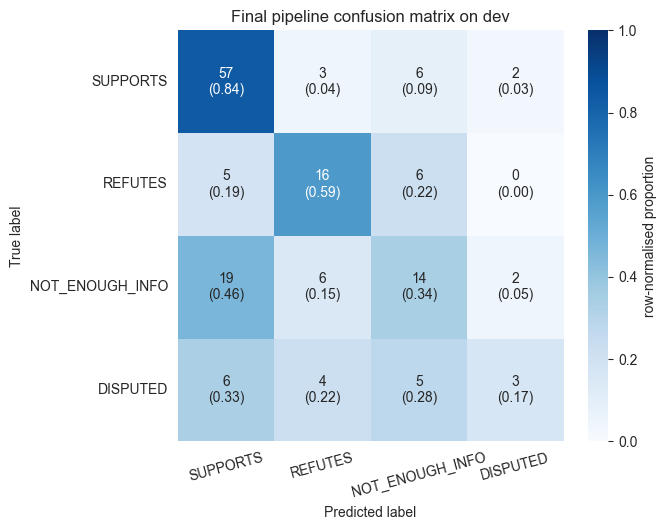

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

FIG_DIR = cfg.FIG_DIR
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_style("whitegrid")

y_true = [dev_claims[cid]["claim_label"] for cid in dev_preds_final]
y_pred = [dev_preds_final[cid]["claim_label"] for cid in dev_preds_final]

print(classification_report(y_true, y_pred, labels=LABELS, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=LABELS)
row_sums = cm.sum(axis=1, keepdims=True)
cm_norm = np.divide(cm, row_sums, where=row_sums > 0, out=np.zeros_like(cm, dtype=float))

annot = np.empty_like(cm, dtype=object)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        annot[i, j] = f"{cm[i, j]}\n({cm_norm[i, j]:.2f})"

fig, ax = plt.subplots(figsize=(6.8, 5.4))
sns.heatmap(
    cm_norm,
    annot=annot,
    fmt="",
    cmap="Blues",
    xticklabels=LABELS,
    yticklabels=LABELS,
    cbar_kws={"label": "row-normalised proportion"},
    vmin=0,
    vmax=1,
    ax=ax,
)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("Final pipeline confusion matrix on dev")
plt.xticks(rotation=15)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrix_pipeline.png", dpi=130, bbox_inches="tight")
plt.show()

In [ ]:
# Where did the model get evidence right but the label wrong (or vice versa)?
labeled_correct, ev_correct = 0, 0
for cid, gold in dev_claims.items():
    if cid not in dev_preds_final:
        continue
    p = dev_preds_final[cid]
    label_ok = p["claim_label"] == gold["claim_label"]
    ev_ok = any(e in gold["evidences"] for e in p["evidences"])
    labeled_correct += int(label_ok)
    ev_correct += int(ev_ok)
n = len(dev_claims)
print(f"claims with at least one correct evidence: {ev_correct}/{n} ({ev_correct / n:.2%})")
print(f"claims with correct label                : {labeled_correct}/{n} ({labeled_correct / n:.2%})")

## Summary

This notebook produces the two prediction files for evaluation, scores dev, and reports a small ablation that quantifies how much the cross-encoder retrieval stage contributes to the final HM score. The chosen evidence cut-off strategy is saved alongside the predictions; reproducing the leaderboard submission only requires rerunning Stage 5 with the checkpoints from Stages 3 and 4.